In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('emails.csv')
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [2]:
df.shape

(5172, 3002)

In [3]:
df.info

<bound method DataFrame.info of        Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  \
0        Email 1    0   0    1    0    0   0    2    0    0  ...         0   
1        Email 2    8  13   24    6    6   2  102    1   27  ...         0   
2        Email 3    0   0    1    0    0   0    8    0    0  ...         0   
3        Email 4    0   5   22    0    5   1   51    2   10  ...         0   
4        Email 5    7   6   17    1    5   2   57    0    9  ...         0   
...          ...  ...  ..  ...  ...  ...  ..  ...  ...  ...  ...       ...   
5167  Email 5168    2   2    2    3    0   0   32    0    0  ...         0   
5168  Email 5169   35  27   11    2    6   5  151    4    3  ...         0   
5169  Email 5170    0   0    1    1    0   0   11    0    0  ...         0   
5170  Email 5171    2   7    1    0    2   1   28    2    0  ...         0   
5171  Email 5172   22  24    5    1    6   5  148    8    2  ...         0   

      jay  valued  lay  infrast

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
df["Prediction"].value_counts()

Prediction
0    3672
1    1500
Name: count, dtype: int64

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(["Email No.", "Prediction"], axis=1)
y = df["Prediction"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(4137, 3000) (1035, 3000)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_predK = knn.predict(X_test)
y_predK[:5]

array([0, 0, 1, 0, 0])

In [15]:
from sklearn.svm import SVC

svm = SVC(kernel="linear")
svm.fit(X_train, y_train)

y_predS = svm.predict(X_test)
y_predS[:10]

array([0, 0, 1, 0, 0, 0, 1, 0, 0, 0])

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("KNN")
print("Accuracy: ", accuracy_score(y_test, y_predK))
print("Precision: ", precision_score(y_test, y_predK))
print("Recall: ", recall_score(y_test, y_predK))
print("F1 Score: ", f1_score(y_test, y_predK))
print("Specificity: ", recall_score(y_test, y_predK, pos_label=0))
print("Error Rate: ", 1-accuracy_score(y_test, y_predK))

print("\nSVM")
print("Accuracy: ", accuracy_score(y_test, y_predS))
print("Precision: ", precision_score(y_test, y_predS))
print("Recall: ", recall_score(y_test, y_predS))
print("F1 Score: ", f1_score(y_test, y_predS))
print("Specificity: ", recall_score(y_test, y_predS, pos_label=0))
print("Error Rate: ", 1-accuracy_score(y_test, y_predS))

KNN
Accuracy:  0.8454106280193237
Precision:  0.6588785046728972
Recall:  0.9527027027027027
F1 Score:  0.7790055248618785
Specificity:  0.8024357239512855
Error Rate:  0.15458937198067635

SVM
Accuracy:  0.9468599033816425
Precision:  0.8950819672131147
Recall:  0.9222972972972973
F1 Score:  0.908485856905158
Specificity:  0.9566982408660352
Error Rate:  0.0531400966183575


In [19]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_predK))
print("\n")
print(confusion_matrix(y_test, y_predS))

[[593 146]
 [ 14 282]]


[[707  32]
 [ 23 273]]


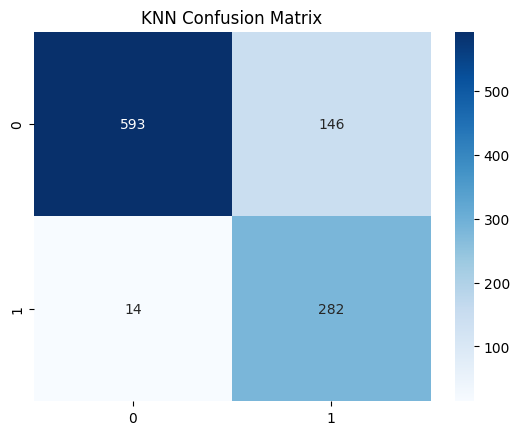

In [20]:
sns.heatmap(confusion_matrix(y_test, y_predK), annot=True, fmt="d", cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

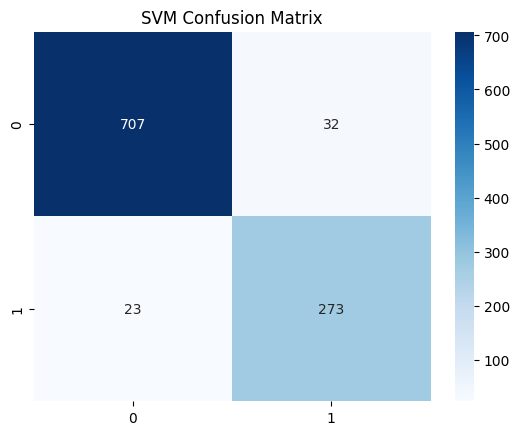

In [21]:
sns.heatmap(confusion_matrix(y_test, y_predS), annot=True, fmt="d", cmap="Blues")
plt.title("SVM Confusion Matrix")
plt.show()